# Parier en France, parier en Ontario

**Deux marchés de jeux en ligne réglementés, deux philosophies.** La France a ouvert en 2010 un marché limité aux paris sportifs, hippiques et au poker, contrôlé depuis 2020 par l'Autorité nationale des jeux (ANJ). L'Ontario a ouvert le sien en avril 2022 à des opérateurs privés, casino en ligne compris, sous la supervision d'iGaming Ontario (iGO) et de la commission des alcools et des jeux (AGCO).

Je veux répondre à quatre questions, avec des données publiques uniquement :

1. Que pèsent les deux marchés, et sur quoi joue-t-on ?
2. Que change une règle comme le plafond français de reversement aux joueurs ?
3. En France, où se trouvent les parieurs sportifs, et le jeu se concentre-t-il dans les territoires les plus modestes ?
4. Comment évoluent les interdictions volontaires de jeu, qui mesurent une partie des difficultés des joueurs ?

Chaque phrase qui va plus loin qu'un comptage est testée, et classée à la fin dans un registre : mesuré, démontré, non démontré, hypothèse.

## 1. Les données

| Source | Contenu | Licence ou conditions |
|---|---|---|
| ANJ sur data.gouv.fr | Joueurs en ligne par département (2024), interdictions volontaires de jeu (2021-2024, et par département 2023-2024), 100 rencontres les plus pariées | Données publiques sur data.gouv.fr |
| ANJ, rapports | *Bilan du marché 2024* (mai 2025), *Rapport annuel 2025* (juin 2026) | Documents publics, chiffres cités avec la page |
| iGaming Ontario | Rapport mensuel du marché, avril 2022 à septembre 2026 (publié en octobre 2026) | Publication publique ; chiffres non audités selon iGO |
| INSEE via data.gouv.fr | Niveau de vie médian et taux de pauvreté par département (2023) | Licence ODbL |
| INSEE | Estimations de population par département, sexe et âge au 1er janvier 2023 | Réutilisation libre avec citation |
| Banque du Canada | Taux de change annuel moyen euro / dollar canadien | Publication publique |

Les fichiers bruts sont dans `donnees/brutes/`. Rien n'est scrapé.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.formula.api as smf

BRUTES = Path("donnees/brutes")
EXPORTS = Path("donnees/exports"); EXPORTS.mkdir(parents=True, exist_ok=True)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)

# Palette du projet : tapis de jeu et ticket de pari
VERT, MOUTARDE, CORAIL, ARDOISE, PAPIER = "#0f4c5c", "#e9b44c", "#e4572e", "#5b6770", "#f4f1ea"
plt.rcParams.update({"figure.facecolor": PAPIER, "axes.facecolor": PAPIER, "savefig.facecolor": PAPIER,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": ARDOISE,
                     "axes.labelcolor": "#2b2b2b", "xtick.color": ARDOISE, "ytick.color": ARDOISE,
                     "font.size": 10.5, "axes.titleweight": "bold", "axes.titlesize": 12})
EUR_CAD_2025 = 1.5782   # dollars canadiens pour 1 euro, moyenne annuelle 2025 (Banque du Canada)

## 2. L'Ontario, mois par mois

Le fichier d'iGO donne, pour chaque mois depuis l'ouverture (4 avril 2022), les mises en argent réel et le revenu brut de jeu non ajusté (NAGGR : mises moins gains, sans les mises payées avec des bonus), au total et par produit (casino, paris, poker entre joueurs). Montants en millions de dollars canadiens, arrondis par iGO.

In [2]:
igo = BRUTES / "iGO_Monthly_Market_Performance_2026-09.xlsx"
tot = pd.read_excel(igo, sheet_name="(Data) Monthly Stats", header=2)
tot = tot.loc[:, ~tot.columns.astype(str).str.startswith("Unnamed")].dropna(subset=["YearMonth"])
tot = tot.rename(columns={"CashWagers(M)": "mises_m", "NAGGR(M)": "revenu_m",
                          "ActivePlayerAccounts(K)": "comptes_k", "ARPPA($)": "revenu_par_compte"})
tot["mois"] = pd.to_datetime(tot["YearMonth"].astype(str))
tot = tot[["mois", "mises_m", "revenu_m", "comptes_k", "revenu_par_compte"]].astype(
    {"mises_m": float, "revenu_m": float, "comptes_k": float, "revenu_par_compte": float})

prod = pd.read_excel(igo, sheet_name="(Data) Product Monthly Stats", header=2)
prod = prod.loc[:, ~prod.columns.astype(str).str.startswith("Unnamed")].dropna(subset=["YearMonth"])
prod = prod.rename(columns={"ProductCategory": "produit", "CashWagers(M)": "mises_m", "NAGGR(M)": "revenu_m"})
prod["mois"] = pd.to_datetime(prod["YearMonth"].astype(str))
prod = prod[["mois", "produit", "mises_m", "revenu_m"]].astype({"mises_m": float, "revenu_m": float})
prod["produit"] = prod["produit"].map({"CASINO": "Casino", "BETTING": "Paris", "P2P POKER": "Poker"})

# Contrôle : la somme des produits doit retrouver le total, aux arrondis près
ctrl = prod.groupby("mois")[["mises_m", "revenu_m"]].sum().join(tot.set_index("mois")[["mises_m", "revenu_m"]], rsuffix="_total")
ecart_mises = (ctrl["mises_m"] - ctrl["mises_m_total"]).abs().max()
ecart_revenu = (ctrl["revenu_m"] - ctrl["revenu_m_total"]).abs().max()
print(f"{tot['mois'].min():%B %Y} à {tot['mois'].max():%B %Y} : {len(tot)} mois")
print(f"Écart maximal produits / total : {ecart_mises:.0f} M$ de mises, {ecart_revenu:.1f} M$ de revenu (arrondis)")

April 2022 à September 2026 : 54 mois
Écart maximal produits / total : 1 M$ de mises, 0.1 M$ de revenu (arrondis)


In [3]:
an = tot.assign(annee=tot["mois"].dt.year).groupby("annee").agg(mois=("mois", "size"), mises_m=("mises_m", "sum"), revenu_m=("revenu_m", "sum"))
an["revenu_eur_m"] = an["revenu_m"] / EUR_CAD_2025
print(an[an["mois"] == 12].round(0).to_string())

p25 = prod[prod["mois"].dt.year == 2025].groupby("produit")[["mises_m", "revenu_m"]].sum()
p25["part_revenu"] = p25["revenu_m"] / p25["revenu_m"].sum()
p25["taux_de_marge"] = p25["revenu_m"] / p25["mises_m"]
print()
print(p25.round(3).to_string())

       mois  mises_m  revenu_m  revenu_eur_m
annee                                       
2023     12  59296.0    2269.0        1438.0
2024     12  77645.0    3006.0        1905.0
2025     12  98382.0    4039.0        2559.0

         mises_m  revenu_m  part_revenu  taux_de_marge
produit                                               
Casino   84507.0    3153.1        0.781          0.037
Paris    12197.0     815.6        0.202          0.067
Poker     1678.0      70.2        0.017          0.042


## 3. Deux marchés, l'année 2025

L'ANJ publie le produit brut des jeux (PBJ : mises moins gains) du marché en ligne français ; iGO publie le NAGGR. Les deux mesurent ce que les opérateurs gardent avant leurs coûts, mais les définitions ne sont pas identiques (traitement des bonus notamment) : la comparaison donne un ordre de grandeur, pas un classement au million près.

**Un piège dans les chiffres français.** Le *Bilan du marché 2024* de l'ANJ donne 1 759 M€ de PBJ des paris sportifs en ligne en 2024 (p. 8-9), mais le *Rapport annuel 2025* donne 1 599 M€ pour la même année 2024 (p. 15), et 1 766 M€ pour 2025. Les deux documents ne précisent pas la raison de l'écart. Je ne mélange donc jamais les deux séries : les années 2019-2024 viennent du *Bilan 2024*, l'année 2025 et son évolution du *Rapport annuel 2025*.

In [4]:
# France : chiffres publiés par l'ANJ (millions d'euros), avec la page de la source
fr_2025 = pd.DataFrame({
    "segment": ["Paris sportifs", "Poker", "Paris hippiques"],
    "pbj_m": [1766, 525, 326],
}).set_index("segment")  # Rapport annuel 2025, p. 15-16 ; total en ligne 2 617 M€ (p. 16)
pbj_fr_2025 = 2617

adultes_fr = pd.read_csv(BRUTES / "open-data-repartition-geographique-des-joueurs-2024.csv", sep=";", encoding="latin-1")[
    "Population adulte INSEE par Département"].sum()
# Ontario : 16 262 121 habitants au 1er juillet 2026 (ministère des Finances de l'Ontario), 85,4 % ont 15 ans ou plus.
# Les 15-24 ans font 12,1 % : on retire trois dixièmes de ce groupe pour approcher les 18 ans et plus (hypothèse d'âges répartis également).
adultes_on = 16_262_121 * (0.854 - 0.121 * 3 / 10)

rev_on_2025_eur = an.loc[2025, "revenu_m"] / EUR_CAD_2025
comp = pd.DataFrame({
    "Revenu des jeux en ligne 2025 (M€)": [pbj_fr_2025, rev_on_2025_eur],
    "Adultes (millions)": [adultes_fr / 1e6, adultes_on / 1e6],
}, index=["France", "Ontario"])
comp["Par adulte (€)"] = comp.iloc[:, 0] / comp.iloc[:, 1]
print(comp.round(1).to_string())
print(f"\nPart du casino dans le revenu ontarien 2025 : {p25.loc['Casino', 'part_revenu']:.0%}")
print(f"Paris seuls, par adulte : France {1766 / (adultes_fr / 1e6):.0f} €, Ontario {p25.loc['Paris', 'revenu_m'] / EUR_CAD_2025 / (adultes_on / 1e6):.0f} €")
print(f"Mises sur les paris, par adulte : France {11517 / (adultes_fr / 1e6):.0f} € (Rapport annuel 2025, p. 16), Ontario {p25.loc['Paris', 'mises_m'] / EUR_CAD_2025 / (adultes_on / 1e6):.0f} €")

         Revenu des jeux en ligne 2025 (M€)  Adultes (millions)  Par adulte (€)
France                               2617.0                53.3            49.1
Ontario                              2559.1                13.3           192.5

Part du casino dans le revenu ontarien 2025 : 78%
Paris seuls, par adulte : France 33 €, Ontario 39 €
Mises sur les paris, par adulte : France 216 € (Rapport annuel 2025, p. 16), Ontario 581 €


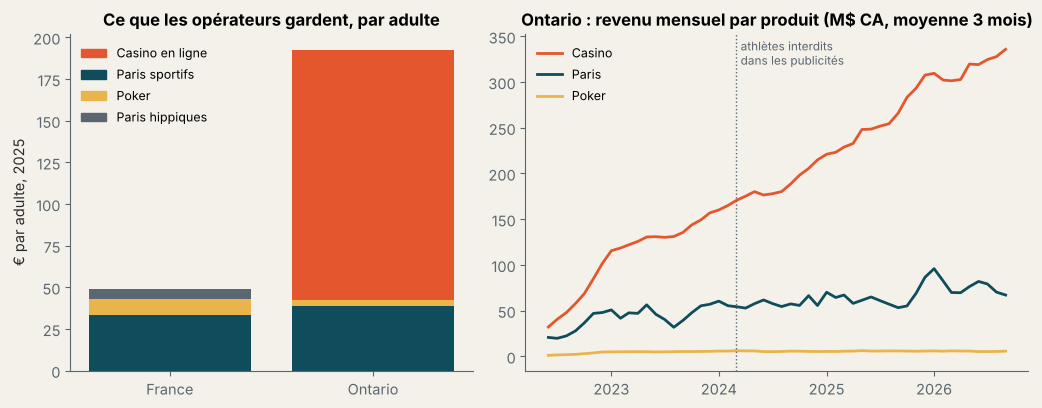

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
on_parts = (p25["revenu_m"] / EUR_CAD_2025 / (adultes_on / 1e6)).reindex(["Casino", "Paris", "Poker"])
fr_parts = (fr_2025["pbj_m"] / (adultes_fr / 1e6))
bas = 0
for seg, col in [("Paris sportifs", VERT), ("Poker", MOUTARDE), ("Paris hippiques", ARDOISE)]:
    ax[0].bar("France", fr_parts[seg], bottom=bas, color=col); bas += fr_parts[seg]
bas = 0
for seg, col, lab in [("Paris", VERT, "Paris"), ("Poker", MOUTARDE, "Poker"), ("Casino", CORAIL, "Casino")]:
    ax[0].bar("Ontario", on_parts[seg], bottom=bas, color=col, label=lab); bas += on_parts[seg]
ax[0].set_ylabel("€ par adulte, 2025")
ax[0].set_title("Ce que les opérateurs gardent, par adulte")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=CORAIL, label="Casino en ligne"), Patch(color=VERT, label="Paris sportifs"),
                      Patch(color=MOUTARDE, label="Poker"), Patch(color=ARDOISE, label="Paris hippiques")],
             frameon=False, fontsize=9, loc="upper left")

m = prod.pivot_table(index="mois", columns="produit", values="revenu_m", aggfunc="sum").rolling(3).mean()
for seg, col in [("Casino", CORAIL), ("Paris", VERT), ("Poker", MOUTARDE)]:
    ax[1].plot(m.index, m[seg], color=col, lw=2, label=seg)
ax[1].axvline(pd.Timestamp("2024-02-28"), color=ARDOISE, ls=":", lw=1)
ax[1].text(pd.Timestamp("2024-03-15"), m["Casino"].max() * 0.95, "athlètes interdits\ndans les publicités", fontsize=8.5, color=ARDOISE)
ax[1].set_title("Ontario : revenu mensuel par produit (M$ CA, moyenne 3 mois)")
import matplotlib.dates as mdates
ax[1].xaxis.set_major_locator(mdates.YearLocator()); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(IMAGES / "deux_marches.png", dpi=150); plt.show()

**Lecture.** En Ontario, le casino en ligne fait l'essentiel du revenu ; en France il est interdit en ligne, et ce sont les paris sportifs qui portent le marché. Ramené au nombre d'adultes, le marché ontarien rapporte environ quatre fois plus aux opérateurs, presque entièrement à cause du casino. Sur les paris sportifs seuls, les deux marchés sont proches (de l'ordre de 33 € par adulte en France et 39 € en Ontario), alors que les Ontariens misent beaucoup plus : la section suivante montre pourquoi les opérateurs français gardent une part plus grande de chaque mise.

## 4. Le plafond français de reversement aux joueurs

En France, un opérateur de paris sportifs en ligne ne peut pas reverser plus de **85 %** des mises aux joueurs sur une année (articles 27 et 28 du décret n° 2020-1349 du 4 novembre 2020 ; délibération de l'ANJ du 1er avril 2021). Autrement dit, il garde au moins 15 % des mises. L'Ontario n'a pas de règle équivalente : les normes de l'AGCO pour le jeu en ligne (Registrar's Standards for Internet Gaming) ne fixent aucun taux de retour minimal ou maximal. Elles demandent seulement d'afficher les cotes et les gains possibles (norme 2.15.2) et de documenter l'avantage de l'opérateur sur chaque mise (norme 4.05).

Si le plafond agit, le taux de marge (PBJ ÷ mises) français doit rester au-dessus de 15 %, et être nettement plus élevé que celui des paris en Ontario.

In [6]:
fr_sport = pd.DataFrame({  # Bilan du marché 2024, p. 9 (millions d'euros)
    "annee": [2019, 2020, 2021, 2022, 2023, 2024],
    "mises_m": [5056, 5352, 7891, 8307, 8490, 10282],
    "pbj_m": [880, 940, 1355, 1389, 1477, 1759],
    "comptes_actifs_k": [3443, 3865, 4474, 4457, 4324, 4882],
    "joueurs_uniques_k": [2373, 2715, 3168, 3307, 3068, 3358],
})
# Contrôle : la mise moyenne par compte 2023 et 2024 citée dans le texte du rapport (1 963 € et 2 106 €)
fr_sport["mise_par_compte"] = fr_sport["mises_m"] * 1000 / fr_sport["comptes_actifs_k"]
fr_sport["taux_de_marge"] = fr_sport["pbj_m"] / fr_sport["mises_m"]
print(fr_sport.round(3).to_string(index=False))
print(f"\n2025 (Rapport annuel 2025, p. 16) : {1766 / 11517:.1%}")

on_bet = prod[prod["produit"] == "Paris"].set_index("mois")
on_bet["taux_de_marge"] = on_bet["revenu_m"] / on_bet["mises_m"]
on_annuel = on_bet.groupby(on_bet.index.year)[["mises_m", "revenu_m"]].sum()
on_annuel["taux_de_marge"] = on_annuel["revenu_m"] / on_annuel["mises_m"]
print("\nOntario, paris, par année civile :")
print(on_annuel.round(3).to_string())
print(f"\nOntario, mois où la marge des paris dépasse 15 % : {(on_bet['taux_de_marge'] > 0.15).sum()} sur {len(on_bet)}")

 annee  mises_m  pbj_m  comptes_actifs_k  joueurs_uniques_k  mise_par_compte  taux_de_marge
  2019     5056    880              3443               2373         1468.487          0.174
  2020     5352    940              3865               2715         1384.735          0.176
  2021     7891   1355              4474               3168         1763.746          0.172
  2022     8307   1389              4457               3307         1863.810          0.167
  2023     8490   1477              4324               3068         1963.460          0.174
  2024    10282   1759              4882               3358         2106.104          0.171

2025 (Rapport annuel 2025, p. 16) : 15.3%

Ontario, paris, par année civile :
      mises_m  revenu_m  taux_de_marge
mois                                  
2022   4583.0     289.7          0.063
2023   9375.0     570.0          0.061
2024  10860.0     687.1          0.063
2025  12197.0     815.6          0.067
2026   9166.0     656.8          0.072

Ont

In [7]:
# Test : les marges annuelles françaises (2019-2025) et ontariennes (années civiles complètes 2023-2025) diffèrent-elles ?
fr_marges = list(fr_sport["taux_de_marge"]) + [1766 / 11517]
on_marges = list(on_annuel.loc[2023:2025, "taux_de_marge"])
u = stats.mannwhitneyu(fr_marges, on_marges, alternative="greater")
print(f"France : {min(fr_marges):.1%} à {max(fr_marges):.1%} ; Ontario : {min(on_marges):.1%} à {max(on_marges):.1%}")
print(f"Mann-Whitney (France > Ontario), {len(fr_marges)} contre {len(on_marges)} années : p = {u.pvalue:.3f}")

France : 15.3% à 17.6% ; Ontario : 6.1% à 6.7%
Mann-Whitney (France > Ontario), 7 contre 3 années : p = 0.008


**Lecture.** Toutes les années françaises sont au-dessus de 15 %, toutes les années ontariennes en dessous : les deux séries ne se chevauchent pas. Le test confirme l'écart malgré le petit nombre d'années. Ce que cela ne prouve pas : que le plafond en soit la seule cause. Le type de paris proposé (combinés, paris en direct) et la concurrence jouent aussi sur la marge. Mais la contrainte légale est cohérente avec ce qu'on observe : à mises égales, un parieur français récupère moins que la plupart des parieurs ontariens.

## 5. En Ontario, l'interdiction des athlètes dans les publicités

Depuis le 28 février 2024, l'AGCO interdit d'utiliser des athlètes, actifs ou retraités, dans les publicités de jeux en ligne, sauf pour promouvoir le jeu responsable (norme 2.03 des *Registrar's Standards for Internet Gaming*). Les paris ont-ils reculé ensuite ?

In [8]:
bet = on_bet.copy()
bet["part_mises"] = bet["mises_m"] / prod.groupby("mois")["mises_m"].sum()
avant = bet.loc["2023-03-01":"2024-02-01", "mises_m"].sum()
apres = bet.loc["2024-03-01":"2025-02-01", "mises_m"].sum()
casino_av = prod[(prod.produit == "Casino")].set_index("mois").loc["2023-03-01":"2024-02-01", "mises_m"].sum()
casino_ap = prod[(prod.produit == "Casino")].set_index("mois").loc["2024-03-01":"2025-02-01", "mises_m"].sum()
print(f"Mises sur les paris, 12 mois avant / après : {avant:,.0f} → {apres:,.0f} M$ ({apres / avant - 1:+.0%})")
print(f"Mises au casino, mêmes périodes : {casino_av:,.0f} → {casino_ap:,.0f} M$ ({casino_ap / casino_av - 1:+.0%})")

# Tendance de la part des paris dans les mises, sur toute la période (corrélation de rang avec le temps)
t = np.arange(len(bet))
r = stats.spearmanr(t, bet["part_mises"])
print(f"Part des paris dans les mises : {bet['part_mises'].iloc[:12].mean():.0%} la première année, "
      f"{bet['part_mises'].iloc[-12:].mean():.0%} les 12 derniers mois ; tendance rho = {r.statistic:.2f}, p = {r.pvalue:.1e}")

Mises sur les paris, 12 mois avant / après : 9,626 → 11,169 M$ (+16%)
Mises au casino, mêmes périodes : 50,711 → 68,196 M$ (+34%)
Part des paris dans les mises : 21% la première année, 11% les 12 derniers mois ; tendance rho = -0.83, p = 4.3e-15


**Lecture.** Les mises sur les paris n'ont pas reculé après l'interdiction : elles ont augmenté, moins vite que celles du casino. La part des paris dans les mises baisse régulièrement depuis l'ouverture du marché, bien avant février 2024 : la tendance est démontrée, son lien avec l'interdiction ne l'est pas. Un avant/après sans groupe de comparaison ne permet pas d'isoler l'effet de la règle, et l'interdiction visait d'abord la protection des mineurs, pas le volume de paris.

## 6. En France, où sont les parieurs sportifs ?

L'ANJ publie, pour chaque département, le nombre de joueurs actifs en ligne en 2024 et la population adulte. J'y ajoute le niveau de vie médian et le taux de pauvreté de 2023 (INSEE, Filosofi), et la part des hommes de 20 à 34 ans parmi les 20 ans et plus (INSEE, estimations au 1er janvier 2023), parce que l'ANJ indique que les parieurs sportifs sont surtout de jeunes hommes.

**Attention, niveau départemental.** Une corrélation entre départements ne dit rien des individus (erreur écologique) : si les départements modestes parient plus, cela ne veut pas dire que les personnes modestes parient plus.

In [9]:
geo = pd.read_csv(BRUTES / "open-data-repartition-geographique-des-joueurs-2024.csv", sep=";", encoding="latin-1")
geo = geo.rename(columns={"Numéro du Département": "dep", "Département": "departement",
                          "Nombre de Joueurs de Paris Sportifs": "parieurs", "Nombre de Joueurs de Poker": "joueurs_poker",
                          "Nombre de joueurs de Paris Hippiques": "joueurs_hippiques",
                          "Population adulte INSEE par Département": "adultes"})
geo["dep"] = geo["dep"].astype(str).str.zfill(2)
geo["densite_paris"] = geo["parieurs"] / geo["adultes"]
geo["densite_poker"] = geo["joueurs_poker"] / geo["adultes"]

def insee(fichier, nom):
    d = pd.read_csv(BRUTES / fichier, dtype={"geocode_departement": str})
    return d.rename(columns={"geocode_departement": "dep", "valeur": nom})[["dep", nom]]

pop = pd.read_excel(BRUTES / "insee_estim_pop_dep_sexe_aq_1975_2023.xls", sheet_name="2023", header=None, skiprows=5)
pop = pop[pop[0].astype(str).str.match(r"^(\d\d|2A|2B|97\d)$")]
# Colonnes : 2 à 22 = ensemble par tranche de 5 ans, 23 à 43 = hommes, 44 à 64 = femmes (21 tranches, la dernière = 100 ans et plus)
ens = pop.iloc[:, 2:23].astype(float); hom = pop.iloc[:, 23:44].astype(float)
pop = pd.DataFrame({"dep": pop[0].astype(str),
                    "part_hommes_20_34": hom.iloc[:, 4:7].sum(axis=1).values / ens.iloc[:, 4:].sum(axis=1).values})

d = (geo.merge(insee("insee_niveau_vie_median_departement.csv", "niveau_vie"), on="dep", how="left")
        .merge(insee("insee_taux_pauvrete_departement.csv", "pauvrete"), on="dep", how="left")
        .merge(pop, on="dep", how="left"))
print(f"{len(geo)} départements dans le fichier ANJ ; codes absents de l'INSEE : {sorted(set(geo['dep']) - set(pop['dep']))}")
dm = d[~d["dep"].str.startswith("97")].dropna(subset=["niveau_vie", "pauvrete", "part_hommes_20_34"])
print(f"Analyse sur {len(dm)} départements métropolitains complets")
print(f"Densité de parieurs sportifs : de {dm['densite_paris'].min():.1%} ({dm.loc[dm['densite_paris'].idxmin(), 'departement']}) "
      f"à {dm['densite_paris'].max():.1%} ({dm.loc[dm['densite_paris'].idxmax(), 'departement']})")

100 départements dans le fichier ANJ ; codes absents de l'INSEE : ['20 (anciennement)']
Analyse sur 94 départements métropolitains complets
Densité de parieurs sportifs : de 3.0% (Creuse) à 8.0% (Pas-de-Calais)


In [10]:
res = {}
for var, lab in [("niveau_vie", "niveau de vie médian"), ("pauvrete", "taux de pauvreté"), ("part_hommes_20_34", "part des hommes de 20 à 34 ans")]:
    r = stats.spearmanr(dm[var], dm["densite_paris"])
    res[lab] = (r.statistic, r.pvalue)
    print(f"Densité de parieurs et {lab} : rho = {r.statistic:+.2f}, p = {r.pvalue:.1e}")

z = dm.assign(**{c: (dm[c] - dm[c].mean()) / dm[c].std() for c in ["niveau_vie", "pauvrete", "part_hommes_20_34"]})
z["densite_pts"] = z["densite_paris"] * 100
ols = smf.ols("densite_pts ~ niveau_vie + pauvrete + part_hommes_20_34", data=z).fit(cov_type="HC1")
print()
print(ols.summary().tables[1])
print(f"R² = {ols.rsquared:.2f} ; coefficients en points de densité pour un écart-type de chaque variable")

Densité de parieurs et niveau de vie médian : rho = +0.31, p = 2.1e-03
Densité de parieurs et taux de pauvreté : rho = +0.22, p = 3.2e-02
Densité de parieurs et part des hommes de 20 à 34 ans : rho = +0.83, p = 6.8e-25

                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             5.4817      0.061     89.392      0.000       5.362       5.602
niveau_vie           -0.1377      0.143     -0.966      0.334      -0.417       0.142
pauvrete              0.1354      0.106      1.275      0.202      -0.073       0.344
part_hommes_20_34     0.8385      0.092      9.106      0.000       0.658       1.019
R² = 0.66 ; coefficients en points de densité pour un écart-type de chaque variable


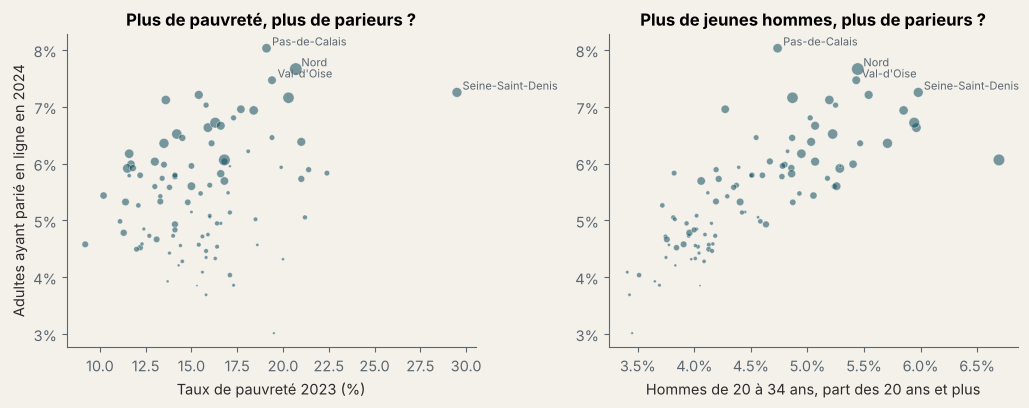

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
for a, var, lab, fmt in [(ax[0], "pauvrete", "Taux de pauvreté 2023 (%)", None),
                          (ax[1], "part_hommes_20_34", "Hommes de 20 à 34 ans, part des 20 ans et plus", mtick.PercentFormatter(1, 1))]:
    a.scatter(dm[var], dm["densite_paris"], s=dm["adultes"] / 25000, color=VERT, alpha=0.55, edgecolor="white", lw=0.5)
    for _, row in dm.nlargest(4, "densite_paris").iterrows():
        a.annotate(row["departement"], (row[var], row["densite_paris"]), fontsize=8, color=ARDOISE, xytext=(4, 2), textcoords="offset points")
    a.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); a.set_xlabel(lab)
    if fmt: a.xaxis.set_major_formatter(fmt)
ax[0].set_ylabel("Adultes ayant parié en ligne en 2024")
ax[0].set_title("Plus de pauvreté, plus de parieurs ?")
ax[1].set_title("Plus de jeunes hommes, plus de parieurs ?")
plt.tight_layout(); plt.savefig(IMAGES / "parieurs_departements.png", dpi=150); plt.show()

**Lecture.** La démographie ressort nettement : plus les hommes de 20 à 34 ans pèsent dans un département, plus il compte de parieurs sportifs (rho = 0,83). Prises seules, la richesse et la pauvreté sont toutes deux faiblement liées à la densité de parieurs, dans le même sens, ce qui est contradictoire : elles captent surtout le fait que les départements urbains sont à la fois plus jeunes, plus riches en moyenne et plus inégaux. Une fois l'âge pris en compte dans la régression, ni le niveau de vie ni la pauvreté n'ont d'effet détectable. Je ne peux donc pas dire que le pari sportif se concentre dans les territoires pauvres, et rien ici ne parle des individus.

## 7. Les interdictions volontaires de jeu

Une personne peut demander à être inscrite au fichier des interdits de jeu, pour au moins trois ans : elle ne peut plus jouer en ligne ni entrer au casino. Le nombre d'inscrits mesure une partie des difficultés de jeu (seulement les personnes qui font la démarche).

In [12]:
iv = pd.read_csv(BRUTES / "anj-nombre-de-personnes-faisant-lobjet-dune-interdiction-volontaire-de-jeux-depuis-2021.csv",
                 sep=";", encoding="latin-1", header=None)
annees = [2021, 2022, 2023, 2024]
inscrits = iv.iloc[2, 1:5].astype(int).values
entrees = iv.iloc[4, 1:5].astype(int).values
sorties = iv.iloc[5, 1:5].astype(int).values
ivn = pd.DataFrame({"annee": annees, "inscrits": inscrits, "entrees": entrees, "sorties": sorties})
print(ivn.to_string(index=False))
print(f"\nInscrits : {inscrits[-1] / inscrits[0] - 1:+.0%} de 2021 à 2024")
print(f"Joueurs uniques en ligne (Bilan 2024, p. 17) : 3 730 000 en 2021, 3 874 000 en 2024 ({3874 / 3730 - 1:+.0%})")
print(f"Paris sportifs, joueurs uniques : {3168} k en 2021, {3358} k en 2024 ({3358 / 3168 - 1:+.0%})")

 annee  inscrits  entrees  sorties
  2021     40000     5415     3439
  2022     46632    10820     3911
  2023     58319    14712     3429
  2024     73439    18932     4573

Inscrits : +84% de 2021 à 2024
Joueurs uniques en ligne (Bilan 2024, p. 17) : 3 730 000 en 2021, 3 874 000 en 2024 (+4%)
Paris sportifs, joueurs uniques : 3168 k en 2021, 3358 k en 2024 (+6%)


In [13]:
raw = pd.read_csv(BRUTES / "anj-donnees-sur-la-repartition-geographique-des-personnes-faisant-lobjet-dune-interdiction-volontaire-de-jeu-depuis-2023.csv",
                  sep=";", header=None, dtype=str, encoding="latin-1")
def bloc(c1, c2, an):
    b = raw.iloc[3:, [c1, c2]].dropna(); b.columns = ["code", "n"]; b["code"] = b["code"].str.strip(); b["n"] = b["n"].astype(int); b["annee"] = an
    return b
ivd = pd.concat([bloc(0, 1, 2023), bloc(3, 4, 2024)])
valide = ivd["code"].str.match(r"^(\d\d|2A|2B)$") & (ivd["code"] != "00") & (ivd["code"] != "98") & (ivd["code"] != "96")
print("Codes de département invalides dans le fichier (saisie) :")
print(ivd[~valide].groupby("annee")["n"].agg(["count", "sum"]).rename(columns={"count": "codes", "sum": "personnes"}).to_string())
print(f"Part des inscrits 2024 rattachés à un département valide : {ivd[valide & (ivd.annee == 2024)]['n'].sum() / ivd[ivd.annee == 2024]['n'].sum():.2%}")

Codes de département invalides dans le fichier (saisie) :
       codes  personnes
annee                  
2023      10         24
2024      14         31
Part des inscrits 2024 rattachés à un département valide : 99.95%


In [14]:
iv24 = ivd[valide & (ivd["annee"] == 2024)].rename(columns={"code": "dep", "n": "interdits_2024"})[["dep", "interdits_2024"]]
iv23 = ivd[valide & (ivd["annee"] == 2023)].rename(columns={"code": "dep", "n": "interdits_2023"})[["dep", "interdits_2023"]]
# Le fichier ANJ regroupe la Corse sous le code 20 : on additionne 2A et 2B côté population pour comparer.
g2 = geo.copy(); g2.loc[g2["dep"].str.startswith("20"), "dep"] = "20"
g2 = g2.groupby("dep", as_index=False)[["adultes", "parieurs"]].sum()
di = g2.merge(iv24, on="dep").merge(iv23, on="dep")
di["interdits_pour_100k"] = di["interdits_2024"] / di["adultes"] * 1e5
di["densite_paris"] = di["parieurs"] / di["adultes"]
di["croissance"] = di["interdits_2024"] / di["interdits_2023"] - 1
print(f"{len(di)} départements appariés")
r = stats.spearmanr(di["densite_paris"], di["interdits_pour_100k"])
print(f"Interdits pour 100 000 adultes et densité de parieurs sportifs : rho = {r.statistic:+.2f}, p = {r.pvalue:.1e}")
print(f"Hausse 2023-2024 : médiane {di['croissance'].median():+.0%}, de {di['croissance'].min():+.0%} à {di['croissance'].max():+.0%}")
top = di.merge(geo[["dep", "departement"]], on="dep", how="left").nlargest(5, "interdits_pour_100k")[["departement", "interdits_pour_100k"]]
print(top.round(0).to_string(index=False))

95 départements appariés
Interdits pour 100 000 adultes et densité de parieurs sportifs : rho = +0.30, p = 3.6e-03
Hausse 2023-2024 : médiane +34%, de +8% à +61%
        departement  interdits_pour_100k
    Alpes-Maritimes                350.0
                Var                253.0
       Haute-Savoie                222.0
Pyrénées-Orientales                222.0
   Bouches-du-Rhône                221.0


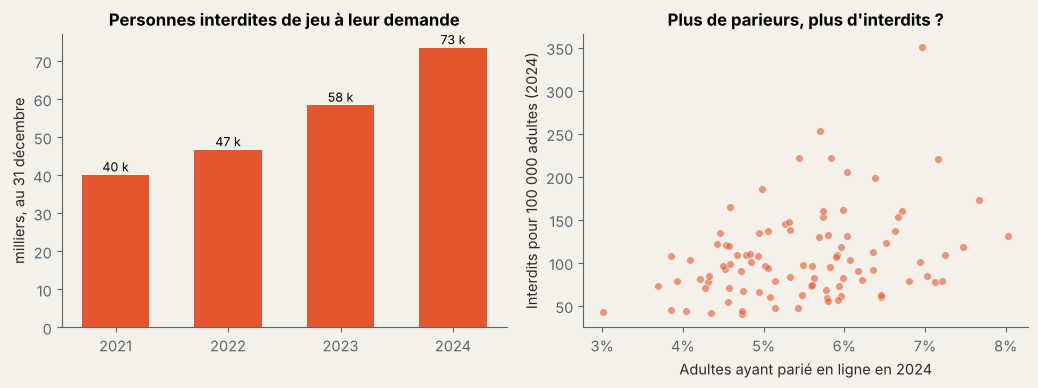

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
ax[0].bar(ivn["annee"].astype(str), ivn["inscrits"] / 1000, color=CORAIL, width=0.6)
for x, y in zip(ivn["annee"].astype(str), ivn["inscrits"] / 1000):
    ax[0].text(x, y + 1, f"{y:.0f} k", ha="center", fontsize=9)
ax[0].set_title("Personnes interdites de jeu à leur demande")
ax[0].set_ylabel("milliers, au 31 décembre")
ax[1].scatter(di["densite_paris"], di["interdits_pour_100k"], color=CORAIL, alpha=0.6, s=30, edgecolor="white", lw=0.5)
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax[1].set_xlabel("Adultes ayant parié en ligne en 2024"); ax[1].set_ylabel("Interdits pour 100 000 adultes (2024)")
ax[1].set_title("Plus de parieurs, plus d'interdits ?")
plt.tight_layout(); plt.savefig(IMAGES / "interdictions.png", dpi=150); plt.show()

**Lecture.** Le nombre d'interdits progresse beaucoup plus vite que le nombre de joueurs en ligne. Cela peut refléter plus de difficultés, mais aussi une démarche mieux connue ou plus simple : les données ne permettent pas de trancher. L'interdiction couvre tous les jeux, y compris les casinos physiques, donc elle ne mesure pas que les paris en ligne.

## 8. Sur quoi parie-t-on ? Les 100 rencontres les plus pariées

L'ANJ publie les 100 rencontres qui ont attiré le plus de mises depuis 2010 (mise à jour d'août 2026).

In [16]:
top100 = pd.read_excel(BRUTES / "20260805-top-100-matchs-les-plus-paries.ods", engine="odf")
top100.columns = ["sport", "match", "competition", "date", "mises", "mises_simples", "mises_vainqueur", "mises_live", "nb_mises", "nb_comptes"]
top100["date"] = pd.to_datetime(top100["date"])
top100["france"] = top100["match"].str.contains(r"\bFRANCE\b")
top100["psg"] = top100["match"].str.contains("PSG")
print(top100["sport"].value_counts().to_string())
print()
print(top100["competition"].value_counts().head(6).to_string())
print(f"\nMatchs de l'équipe de France : {top100['france'].sum()} ; matchs du PSG : {top100['psg'].sum()}")
print(f"Matchs joués depuis 2022 : {(top100['date'].dt.year >= 2022).sum()} sur 100")
print(f"Mise moyenne par compte : {top100['mises'].sum() / top100['nb_comptes'].sum():.0f} € ; part du direct : {top100['mises_live'].sum() / top100['mises'].sum():.0%}")
r = stats.spearmanr(top100["date"].astype("int64"), top100["mises_live"] / top100["mises"])
print(f"Part des mises en direct et date du match : rho = {r.statistic:+.2f}, p = {r.pvalue:.1e}")

sport
Football    99
Tennis       1

competition
Coupe du Monde                        51
Ligue des Champions                   25
Euro                                  17
Coupe intercontinentale de la FIFA     2
Ligue des Nations de l'UEFA            2
Championnat de France                  2

Matchs de l'équipe de France : 24 ; matchs du PSG : 22
Matchs joués depuis 2022 : 83 sur 100
Mise moyenne par compte : 24 € ; part du direct : 23%
Part des mises en direct et date du match : rho = +0.44, p = 4.5e-06


**Lecture.** Le football écrase tout (99 rencontres sur 100), porté par l'équipe de France et le PSG. Le classement est biaisé vers les années récentes, puisque le marché grandit chaque année : 83 rencontres sur 100 datent de 2022 ou après. Ce n'est donc pas la preuve d'un intérêt plus fort pour les matchs récents. En revanche, parmi ces 100 rencontres, la part des mises placées pendant le match augmente nettement avec le temps.

## 9. Ce que le marché légal ne voit pas, et ce que l'État encaisse

Trois questions qu'un régulateur ou un opérateur poserait tout de suite : quelle part du jeu échappe au marché agréé, qui domine le marché légal, et combien l'État prélève. Les chiffres viennent des régulateurs ou d'études publiées ; ils sont recopiés avec leur source dans `donnees/releves/marche_illegal_et_prelevements.csv`.

In [17]:
rel = pd.read_csv(Path("donnees/releves") / "marche_illegal_et_prelevements.csv")
print(rel[["marche", "periode", "indicateur", "valeur_basse", "valeur_haute", "unite"]].to_string(index=False))

legal_2023 = rel.query("indicateur == 'PBJ légal en ligne'").valeur_basse.iloc[0]
ill = rel.query("indicateur == 'PBJ du marché illégal en ligne' and periode.str.startswith('2023')")
print(f"\nFrance 2023 : le jeu illégal en ligne équivaudrait à {ill.valeur_basse.iloc[0] / legal_2023:.0%} à {ill.valeur_haute.iloc[0] / legal_2023:.0%} du jeu légal en ligne")

taux_fr = rel.query("marche == 'France' and indicateur.str.startswith('Prélèvements')").valeur_basse.iloc[0] / 100
prel_fr = 1766 * taux_fr
n0 = lambda v: f"{v:,.0f}".replace(",", " ")
print(f"France : au taux en vigueur depuis juillet 2025 ({taux_fr:.1%}), le PBJ 2025 des paris sportifs en ligne (1 766 M€) donnerait {n0(prel_fr)} M€ de prélèvements sur une année pleine, soit {prel_fr * 1e6 / adultes_fr:.0f} € par adulte")
part_igo = rel.query("indicateur.str.startswith('Part du revenu')").valeur_basse.iloc[0] / 100
igo = an.loc[2025, "revenu_m"] * part_igo / EUR_CAD_2025
print(f"Ontario : environ {part_igo:.0%} du revenu de jeu reste à iGaming Ontario ; appliqué au revenu 2025 (casino compris), {n0(igo)} M€, soit {igo * 1e6 / adultes_on:.0f} € par adulte, avant les frais d'iGO")

 marche                      periode                                                              indicateur  valeur_basse  valeur_haute              unite
 France          2023 (janvier-mars)                                          PBJ du marché illégal en ligne         748.0        1500.0                 M€
 France                         2023               Joueurs sur une offre illégale au moins une fois par mois     3000000.0     3000000.0          personnes
 France                         2025                                          PBJ du marché illégal en ligne        2000.0        2000.0                 M€
 France                         2023                                                      PBJ légal en ligne        2315.0        2315.0                 M€
 France                         2025                                           URL d'offre illégale bloquées        1688.0        1688.0                URL
Ontario                         2023   Taux de canalisation (jou

**Ce que ces chiffres disent.** En France, l'étude commandée par l'ANJ estimait en 2023 le jeu illégal en ligne entre 748 M€ et 1,5 Md€ de produit brut des jeux, soit l'équivalent d'un tiers à deux tiers du jeu légal en ligne de la même année. L'association des opérateurs agréés avance 2 Md€ pour 2025, mais c'est une partie intéressée : je cite le chiffre sans le reprendre à mon compte.

En Ontario, la mesure n'est pas la même : un sondage Ipsos compte la part des joueurs qui ont parié au moins une fois sur un site agréé (91 % en 2026). Un joueur qui mise 5 $ sur un site agréé et 10 000 $ ailleurs compte comme « canalisé ». Les deux pays ne peuvent donc pas être comparés sur ce point.

Côté État, les modèles diffèrent : en France, l'État prélève par l'impôt (59,3 % du produit brut des paris sportifs en ligne depuis juillet 2025, toutes taxes et contributions comprises) ; en Ontario, la province encaisse comme exploitant, via iGaming Ontario qui garde environ 20 % du revenu de jeu et lui a versé 181 M$ de dividende en 2024-2025. Mes deux calculs par adulte sont des ordres de grandeur sur des bases différentes (paris seuls en France, tous les jeux en Ontario).

**Les parts de marché des opérateurs** (Betclic, Winamax, FDJ United avec Parions Sport et Unibet…) ne sont publiées ni par l'ANJ ni par iGO : seuls des cabinets privés les estiment. Je ne les reprends pas, faute de source vérifiable.

## 10. Ce qui est démontré, et ce qui ne l'est pas

| Affirmation | Statut | Preuve |
|---|---|---|
| En Ontario, le casino fait l'essentiel du revenu des jeux en ligne | **Mesuré** | iGO, 2025 (section 3) |
| Rapporté aux adultes, le marché ontarien est plus gros que le marché français | **Mesuré, ordre de grandeur** | Définitions PBJ / NAGGR proches mais pas identiques ; population ontarienne adulte estimée |
| Sur les paris seuls, le revenu par adulte est proche dans les deux marchés | **Mesuré, ordre de grandeur** | Mêmes réserves |
| La marge des paris est plus élevée en France qu'en Ontario | **Démontré** | Aucune année ne se chevauche ; Mann-Whitney (section 4) |
| Le plafond légal de 85 % en est la cause | **Hypothèse cohérente, non démontrée** | Le type de paris et la concurrence jouent aussi |
| L'interdiction des athlètes a fait baisser les paris en Ontario | **Non démontré** | Les mises ont augmenté après ; avant/après sans comparaison |
| La part des paris recule en Ontario depuis 2022 | **Démontré** (tendance) | Corrélation de rang avec le temps (section 5) |
| Les départements où les jeunes hommes pèsent plus comptent plus de parieurs | **Démontré** (niveau départemental) | Spearman et régression (section 6) |
| Le pari sportif se concentre dans les départements pauvres | **Non démontré** | Aucun effet du niveau de vie ni de la pauvreté une fois l'âge pris en compte |
| Les personnes pauvres parient plus | **Non démontrable ici** | Données agrégées : erreur écologique |
| Les départements avec plus de parieurs comptent plus d'interdits | **Démontré**, lien modéré (niveau départemental) | Spearman (section 7) |
| Dans le top 100, la part des mises en direct augmente avec le temps | **Démontré** (sur ces 100 rencontres) | Spearman (section 8) |
| Les interdictions volontaires augmentent plus vite que les joueurs | **Mesuré** | ANJ, 2021-2024 (section 7) |
| Plus de difficultés de jeu en France | **Hypothèse** | La hausse peut aussi venir d'une démarche plus connue |
| L'ANJ publie deux valeurs du PBJ 2024 des paris sportifs | **Mesuré** | 1 759 M€ (Bilan 2024) contre 1 599 M€ (Rapport annuel 2025) |
| Le jeu illégal en ligne pèse entre 748 M€ et 1,5 Md€ en France (2023) | **Estimation publiée** (PwC pour l'ANJ), non mesurée ici | Section 9 |
| 91 % des joueurs ontariens jouent sur au moins un site agréé (2026) | **Sondage publié** (Ipsos), ne mesure pas la part des mises | Section 9 |
| L'État prélève 59,3 % du PBJ des paris sportifs en ligne depuis juillet 2025 | **Mesuré** (taux publié par l'ANJ) | Section 9 |

Les valeurs exactes des tests sont dans les sorties ci-dessus ; le README les reprend.

## 11. Exports pour SQL et Power BI

In [18]:
tot.to_csv(EXPORTS / "ontario_mensuel.csv", index=False)
prod.to_csv(EXPORTS / "ontario_mensuel_produits.csv", index=False)
fr_sport.to_csv(EXPORTS / "france_paris_sportifs_annuel.csv", index=False)
d[["dep", "departement", "parieurs", "joueurs_poker", "joueurs_hippiques", "adultes", "niveau_vie", "pauvrete", "part_hommes_20_34", "densite_paris"]].to_csv(EXPORTS / "france_departements.csv", index=False)
di.to_csv(EXPORTS / "france_interdits_departements.csv", index=False)
ivn.to_csv(EXPORTS / "france_interdits_annuel.csv", index=False)
top100.drop(columns=["france", "psg"]).assign(equipe_de_france=top100["france"], psg=top100["psg"]).to_csv(EXPORTS / "top100_rencontres.csv", index=False)
print(sorted(p.name for p in EXPORTS.glob("*.csv")))

['evenements_reglementaires.csv', 'france_departements.csv', 'france_interdits_annuel.csv', 'france_interdits_departements.csv', 'france_paris_sportifs_annuel.csv', 'ontario_mensuel.csv', 'ontario_mensuel_produits.csv', 'suivi_indicateurs.csv', 'suivi_ontario_paris_mensuel.csv', 'top100_rencontres.csv']
